<a href="https://colab.research.google.com/github/cmkarthik2004/AF05148725---Event-Management-System/blob/main/Apache_Spark_Kaggle_Online_Retail_Beginner_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Apache Spark from Basics to Real-Time Processing
## Kaggle Online Retail project using PySparkY
AUTHOR" C M KARTHIK


**Beginner level | Google Colab | Practical seminar project**

This notebook explains how Spark starts, loads a real dataset, understands and cleans it, divides it into partitions, processes it, analyses business results, plans execution, visualises findings, and handles continuously arriving data.

**Important:** The Kaggle CSV is historical data (batch processing). The final section uses Spark's built-in rate source to simulate live incoming data. It is not a live Kaggle feed.

## 0. How to run
1. Open [Google Colab](https://colab.research.google.com/).
2. Select **File → Upload notebook** and upload this notebook.
3. Run cells from top to bottom.
4. Practise once before your seminar.

## 1. Apache Spark basics

**Apache Spark** is a data-processing engine. It reads data, performs computations and produces results. It is designed to handle large datasets by dividing work into partitions and processing them in parallel.

| Term | Easy meaning |
|---|---|
| Big Data | Data too large or complex for traditional single-machine processing |
| DataFrame | Data arranged in rows and named columns, like a table |
| Partition | A chunk of data Spark can process separately |
| Driver | Coordinates a Spark application |
| Executor | Performs tasks for the application |
| Cluster | Multiple computers working together |
| Batch processing | Processing stored data as a collection |
| Streaming | Processing data that keeps arriving |

**How Spark works:** Driver plans and coordinates work → data is split into partitions → tasks process partitions → results are returned or saved.

In this Colab project, `local[*]` uses available CPU cores on one computer. It demonstrates Spark concepts, but it is not a multi-computer cluster.

## 2. Install Java and required Python packages
Spark runs on the Java Virtual Machine. PySpark lets us use Spark through Python.

In [ ]:
!apt-get -qq update
!apt-get -qq install -y openjdk-17-jdk-headless
!pip -q install pyspark kagglehub pandas matplotlib

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-17-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-17-jre-headless_17.0.20.1+1-1~24.04_amd64.deb ...
Unpacking openjdk-17-jre-headless:amd64 (17.0.20.1+1-1~24.04) ...
Selecting previously unselected package openjdk-17-jdk-headless:amd64.
Preparing to unpack .../openjdk-17-jdk-headless_17.0.20.1+1-1~24.04_amd64.deb ...
Unpacking openjdk-17-jdk-headless:amd64 (17.0.20.1+1-1~24.04) ...
Setting up openjdk-17-jre-headless:amd64 (17.0.20.1+1-1~24.04) ...
Processing triggers for ca-certificates-java (20240118) ...
[0.018s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.018s

In [ ]:
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
!java -version

import pyspark
print("PySpark version:", pyspark.__version__)

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
PySpark version: 4.0.4


## 3. Start Spark
`SparkSession` is the main entry point. `appName()` names the application. `local[*]` uses available local CPU cores. `getOrCreate()` creates or reuses a session.

In [ ]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("OnlineRetailSparkSeminar")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

print("Spark started!")
print("Spark version:", spark.version)
print("Application:", spark.sparkContext.appName)
print("Master:", spark.sparkContext.master)

Spark started!
Spark version: 4.0.4
Application: OnlineRetailSparkSeminar
Master: local[*]


### Spark architecture in simple terms
- **Driver:** coordinator; plans work and requests execution.
- **Executors:** processes that perform tasks.
- **Partitions:** chunks of data.
- **Task:** work on one partition.
- **Stage:** a group of tasks.
- **Job:** work triggered by an action such as `count()` or `show()`.

In a real cluster, executors can run on worker machines. In our Colab demo, execution is local.

## 4. Download the Kaggle dataset using KaggleHub

Dataset: [Kaggle – Ecommerce Data](https://www.kaggle.com/datasets/carrie1/ecommerce-data)

We use the dataset identifier you supplied: `carrie1/ecommerce-data`. KaggleHub downloads the latest available version and returns its folder path. If Kaggle requires authentication, follow its secure KaggleHub instructions. Never publish your Kaggle API token.

In [ ]:
import kagglehub
from pathlib import Path

# Download latest version
dataset_path = kagglehub.dataset_download("carrie1/ecommerce-data")
print("Path to dataset files:", dataset_path)

# Find CSV files without assuming the exact filename
csv_files = list(Path(dataset_path).rglob("*.csv"))
print("CSV files found:", csv_files)

if not csv_files:
    raise FileNotFoundError("No CSV file found in the downloaded dataset.")

preferred = [p for p in csv_files if p.name.lower() == "data.csv"]
csv_path = str(preferred[0] if preferred else csv_files[0])
print("Using:", csv_path)

Using Colab cache for faster access to the 'ecommerce-data' dataset.
Path to dataset files: /kaggle/input/ecommerce-data
CSV files found: [PosixPath('/kaggle/input/ecommerce-data/data.csv')]
Using: /kaggle/input/ecommerce-data/data.csv


## 5. Load the CSV into a Spark DataFrame

- `header=True`: first row contains column names.
- `inferSchema=True`: Spark infers data types from values.
- `encoding`: specifies character encoding.
- `show(10)`: displays 10 records.

This is the first main practical moment: Spark reads a real CSV and represents it as a DataFrame.

In [ ]:
df_raw = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("encoding", "ISO-8859-1")
    .csv(csv_path)
)

print("Dataset loaded!")
df_raw.show(10, truncate=False)

Dataset loaded!
+---------+---------+-----------------------------------+--------+--------------+---------+----------+--------------+
|InvoiceNo|StockCode|Description                        |Quantity|InvoiceDate   |UnitPrice|CustomerID|Country       |
+---------+---------+-----------------------------------+--------+--------------+---------+----------+--------------+
|536365   |85123A   |WHITE HANGING HEART T-LIGHT HOLDER |6       |12/1/2010 8:26|2.55     |17850     |United Kingdom|
|536365   |71053    |WHITE METAL LANTERN                |6       |12/1/2010 8:26|3.39     |17850     |United Kingdom|
|536365   |84406B   |CREAM CUPID HEARTS COAT HANGER     |8       |12/1/2010 8:26|2.75     |17850     |United Kingdom|
|536365   |84029G   |KNITTED UNION FLAG HOT WATER BOTTLE|6       |12/1/2010 8:26|3.39     |17850     |United Kingdom|
|536365   |84029E   |RED WOOLLY HOTTIE WHITE HEART.     |6       |12/1/2010 8:26|3.39     |17850     |United Kingdom|
|536365   |22752    |SET 7 BABUSHKA NEST

**Explain to the audience:** Each row is a transaction record. Columns describe invoice, product, quantity, date, price, customer and country. A DataFrame is like a table, but Spark can distribute its processing.

## 6. Understand the data
Inspect row count, column count, schema, data types and summary statistics. `count()` is an action and triggers computation.

In [ ]:
row_count = df_raw.count()
print("Rows:", row_count)
print("Columns:", len(df_raw.columns))
print("Column names:", df_raw.columns)
df_raw.printSchema()

Rows: 541909
Columns: 8
Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
root
 |-- InvoiceNo: string (nullable = true)
 |-- StockCode: string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- InvoiceDate: string (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- CustomerID: integer (nullable = true)
 |-- Country: string (nullable = true)



In [ ]:
df_raw.describe().show(truncate=False)

+-------+------------------+------------------+------------------------------+------------------+---------------+-----------------+------------------+-----------+
|summary|InvoiceNo         |StockCode         |Description                   |Quantity          |InvoiceDate    |UnitPrice        |CustomerID        |Country    |
+-------+------------------+------------------+------------------------------+------------------+---------------+-----------------+------------------+-----------+
|count  |541909            |541909            |540455                        |541909            |541909         |541909           |406829            |541909     |
|mean   |559965.752026781  |27623.240210938104|20713.0                       |9.55224954743324  |NULL           |4.611113626082972|15287.690570239585|NULL       |
|stddev |13428.417280800133|16799.73762842775 |NULL                          |218.08115785023486|NULL           |96.7598530611797 |1713.600303321594 |NULL       |
|min    |536365       

### 6.1 Count missing values

In [ ]:
from pyspark.sql.functions import col, sum as spark_sum

missing_counts = df_raw.select([
    spark_sum(col(c).isNull().cast("int")).alias(c)
    for c in df_raw.columns
])
missing_counts.show(truncate=False)

+---------+---------+-----------+--------+-----------+---------+----------+-------+
|InvoiceNo|StockCode|Description|Quantity|InvoiceDate|UnitPrice|CustomerID|Country|
+---------+---------+-----------+--------+-----------+---------+----------+-------+
|0        |0        |1454       |0       |0          |0        |135080    |0      |
+---------+---------+-----------+--------+-----------+---------+----------+-------+



## 7. Clean the data

For this beginner analysis:
1. Remove rows missing essential transaction fields.
2. Remove duplicate rows.
3. Keep positive quantities and prices for the sales analysis.
4. Convert date, quantity and price to suitable types.

**Business caution:** Negative quantities can represent returns or credit notes. We exclude them from this simple positive-sales analysis, but a real retailer should analyse returns separately.

In [ ]:
from pyspark.sql.functions import (
    col, to_timestamp, date_format, desc, count as spark_count,
    round as spark_round, spark_partition_id
)

required = ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate", "UnitPrice", "Country"]
missing_cols = [c for c in required if c not in df_raw.columns]
if missing_cols:
    raise ValueError(f"Expected columns missing: {missing_cols}")

df_clean = (
    df_raw
    .dropna(subset=required)
    .dropDuplicates()
    .withColumn("Quantity", col("Quantity").cast("double"))
    .withColumn("UnitPrice", col("UnitPrice").cast("double"))
    .withColumn("InvoiceDate", to_timestamp(col("InvoiceDate"), "M/d/yyyy H:mm"))
    .filter((col("Quantity") > 0) & (col("UnitPrice") > 0))
    .filter(col("InvoiceDate").isNotNull())
)

print("Rows before cleaning:", row_count)
print("Rows after cleaning:", df_clean.count())
print("Rows removed:", row_count - df_clean.count())
df_clean.show(10, truncate=False)

Rows before cleaning: 541909
Rows after cleaning: 524878
Rows removed: 17031
+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+
|InvoiceNo|StockCode|Description                        |Quantity|InvoiceDate        |UnitPrice|CustomerID|Country       |
+---------+---------+-----------------------------------+--------+-------------------+---------+----------+--------------+
|536365   |85123A   |WHITE HANGING HEART T-LIGHT HOLDER |6.0     |2010-12-01 08:26:00|2.55     |17850     |United Kingdom|
|536365   |84029G   |KNITTED UNION FLAG HOT WATER BOTTLE|6.0     |2010-12-01 08:26:00|3.39     |17850     |United Kingdom|
|536367   |22748    |POPPY'S PLAYHOUSE KITCHEN          |6.0     |2010-12-01 08:34:00|2.1      |13047     |United Kingdom|
|536367   |22623    |BOX OF VINTAGE JIGSAW BLOCKS       |3.0     |2010-12-01 08:34:00|4.95     |13047     |United Kingdom|
|536368   |22960    |JAM MAKING SET WITH JARS           |6.0  

## 8. Data partitioning: how Spark divides work

A partition is a logical chunk of data that Spark can process separately. We deliberately create four partitions for demonstration.

`repartition(4)` redistributes records and causes a shuffle, so it has a cost. It is useful here to show the concept, but should not be added automatically to every real workflow.

In [ ]:
df_partitioned = df_clean.repartition(4)
print("Number of partitions:", df_partitioned.rdd.getNumPartitions())

partition_counts = (
    df_partitioned
    .withColumn("partition_id", spark_partition_id())
    .groupBy("partition_id")
    .count()
    .orderBy("partition_id")
)
partition_counts.show()

Number of partitions: 4
+------------+------+
|partition_id| count|
+------------+------+
|           0|131219|
|           1|131220|
|           2|131220|
|           3|131219|
+------------+------+



In [ ]:
from pyspark.sql.functions import spark_partition_id

for n in [2, 4, 8]:

    print(f"\n========== {n} PARTITIONS ==========")

    temp_df = df_clean.repartition(n)

    print("Total partitions:",
          temp_df.rdd.getNumPartitions())

    temp_df.withColumn(
        "partition_id",
        spark_partition_id()
    ).groupBy(
        "partition_id"
    ).count().orderBy(
        "partition_id"
    ).show()


========== 2 PARTITIONS ==========
Total partitions: 2
+------------+------+
|partition_id| count|
+------------+------+
|           0|262439|
|           1|262439|
+------------+------+


========== 4 PARTITIONS ==========
Total partitions: 4
+------------+------+
|partition_id| count|
+------------+------+
|           0|131219|
|           1|131220|
|           2|131220|
|           3|131219|
+------------+------+


========== 8 PARTITIONS ==========
Total partitions: 8
+------------+-----+
|partition_id|count|
+------------+-----+
|           0|65609|
|           1|65609|
|           2|65610|
|           3|65610|
|           4|65610|
|           5|65610|
|           6|65610|
|           7|65610|
+------------+-----+



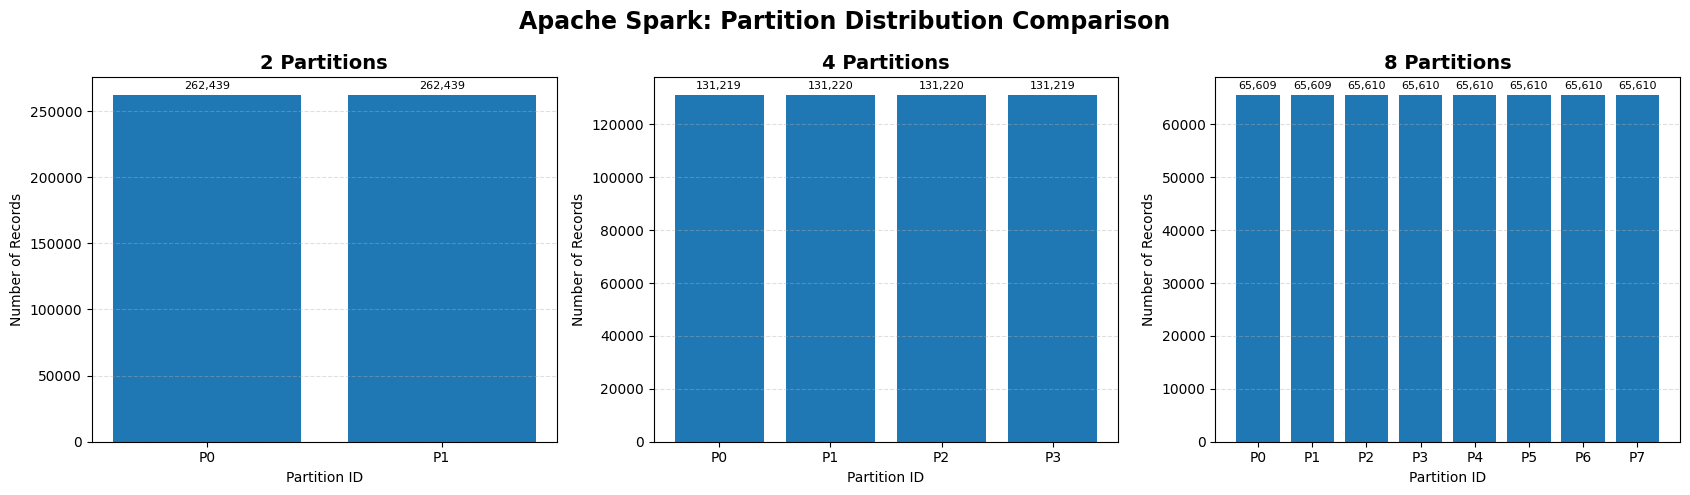

In [ ]:
import matplotlib.pyplot as plt
from pyspark.sql.functions import spark_partition_id

# Different partition configurations
partition_options = [2, 4, 8]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, n in zip(axes, partition_options):

    # Create DataFrame with n partitions
    temp_df = df_clean.repartition(n)

    # Get actual record count in each partition
    counts = (
        temp_df
        .withColumn("partition_id", spark_partition_id())
        .groupBy("partition_id")
        .count()
        .orderBy("partition_id")
        .collect()
    )

    partition_ids = [row["partition_id"] for row in counts]
    record_counts = [row["count"] for row in counts]

    # Draw bar chart
    bars = ax.bar(
        [f"P{i}" for i in partition_ids],
        record_counts
    )

    ax.set_title(f"{n} Partitions", fontsize=14, fontweight="bold")
    ax.set_xlabel("Partition ID")
    ax.set_ylabel("Number of Records")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    # Show count above each bar
    ax.bar_label(
        bars,
        labels=[f"{v:,}" for v in record_counts],
        padding=3,
        fontsize=8
    )

plt.suptitle(
    "Apache Spark: Partition Distribution Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Explain:** You should see partition IDs and the number of rows in each. The distribution may not be exactly equal. Spark can schedule tasks for different partitions in parallel.

In [ ]:
from pyspark.sql.functions import spark_partition_id, col, to_timestamp
from pyspark.sql import SparkSession
import kagglehub
from pathlib import Path

# Ensure we have an active SparkSession and df_clean is defined
if 'df_clean' not in locals():
    print("Spark session was stopped or df_clean is missing. Re-initializing...")

    # Dynamically find or download the dataset path
    try:
        dataset_path = kagglehub.dataset_download("carrie1/ecommerce-data")
    except Exception:
        dataset_path = "/kaggle/input/ecommerce-data"

    csv_files = list(Path(dataset_path).rglob("*.csv"))
    if not csv_files:
        raise FileNotFoundError("No CSV file found in the dataset folder.")

    preferred = [p for p in csv_files if p.name.lower() == "data.csv"]
    resolved_csv_path = str(preferred[0] if preferred else csv_files[0])

    spark = (
        SparkSession.builder
        .appName("OnlineRetailSparkSeminar")
        .master("local[*]")
        .config("spark.sql.shuffle.partitions", "4")
        .getOrCreate()
    )
    # Re-load
    df_raw = (
        spark.read
        .option("header", True)
        .option("inferSchema", True)
        .option("encoding", "ISO-8859-1")
        .csv(resolved_csv_path)
    )
    # Re-clean
    required = ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate", "UnitPrice", "Country"]
    df_clean = (
        df_raw
        .dropna(subset=required)
        .dropDuplicates()
        .withColumn("Quantity", col("Quantity").cast("double"))
        .withColumn("UnitPrice", col("UnitPrice").cast("double"))
        .withColumn("InvoiceDate", to_timestamp(col("InvoiceDate"), "M/d/yyyy H:mm"))
        .filter((col("Quantity") > 0) & (col("UnitPrice") > 0))
        .filter(col("InvoiceDate").isNotNull())
    )

# Create four partitions
df_partitioned = df_clean.repartition(4)

# Display the records belonging to each partition
partition_details = (
    df_partitioned
    .withColumn(
        "Partition_ID",
        spark_partition_id()
    )
    .groupBy("Partition_ID")
    .count()
    .orderBy("Partition_ID")
)

partition_details.show()

# Trigger an actual Spark action
print("Total records:", df_partitioned.count())

Spark session was stopped or df_clean is missing. Re-initializing...
Using Colab cache for faster access to the 'ecommerce-data' dataset.
+------------+------+
|Partition_ID| count|
+------------+------+
|           0|131219|
|           1|131220|
|           2|131220|
|           3|131219|
+------------+------+

Total records: 524878


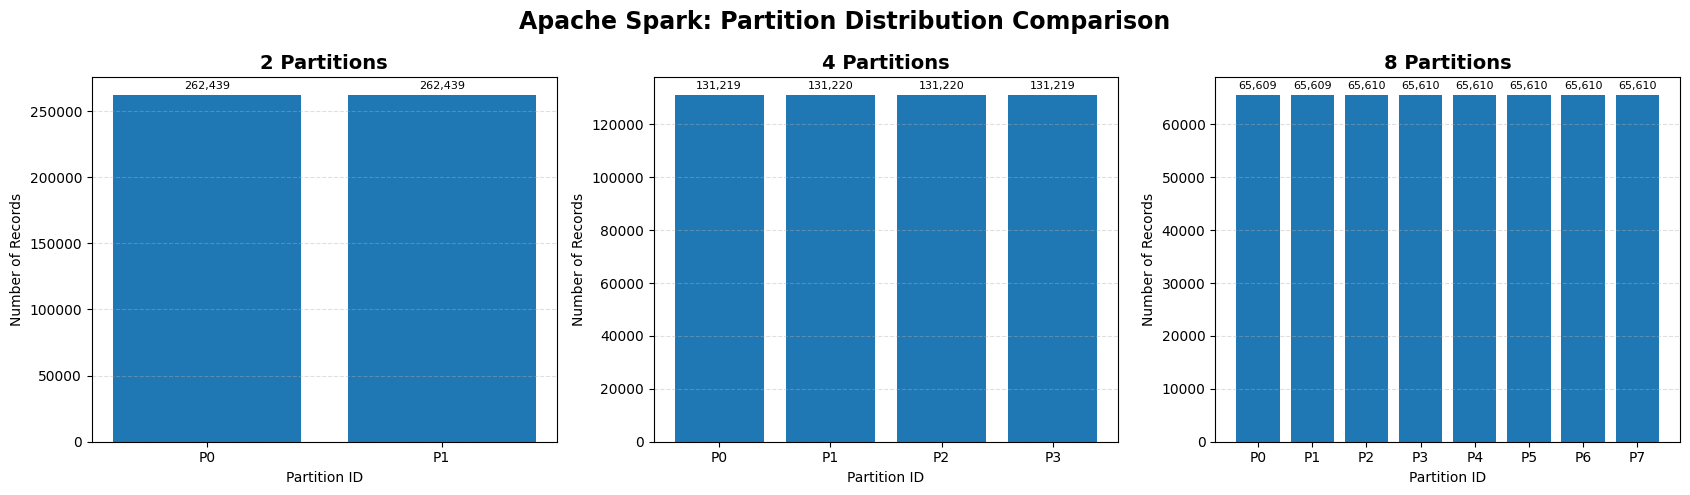

In [ ]:
import matplotlib.pyplot as plt
from pyspark.sql.functions import spark_partition_id

# Different partition configurations
partition_options = [2, 4, 8]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, n in zip(axes, partition_options):

    # Create DataFrame with n partitions
    temp_df = df_clean.repartition(n)

    # Get actual record count in each partition
    counts = (
        temp_df
        .withColumn("partition_id", spark_partition_id())
        .groupBy("partition_id")
        .count()
        .orderBy("partition_id")
        .collect()
    )

    partition_ids = [row["partition_id"] for row in counts]
    record_counts = [row["count"] for row in counts]

    # Draw bar chart
    bars = ax.bar(
        [f"P{i}" for i in partition_ids],
        record_counts
    )

    ax.set_title(f"{n} Partitions", fontsize=14, fontweight="bold")
    ax.set_xlabel("Partition ID")
    ax.set_ylabel("Number of Records")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    # Show count above each bar
    ax.bar_label(
        bars,
        labels=[f"{v:,}" for v in record_counts],
        padding=3,
        fontsize=8
    )

plt.suptitle(
    "Apache Spark: Partition Distribution Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

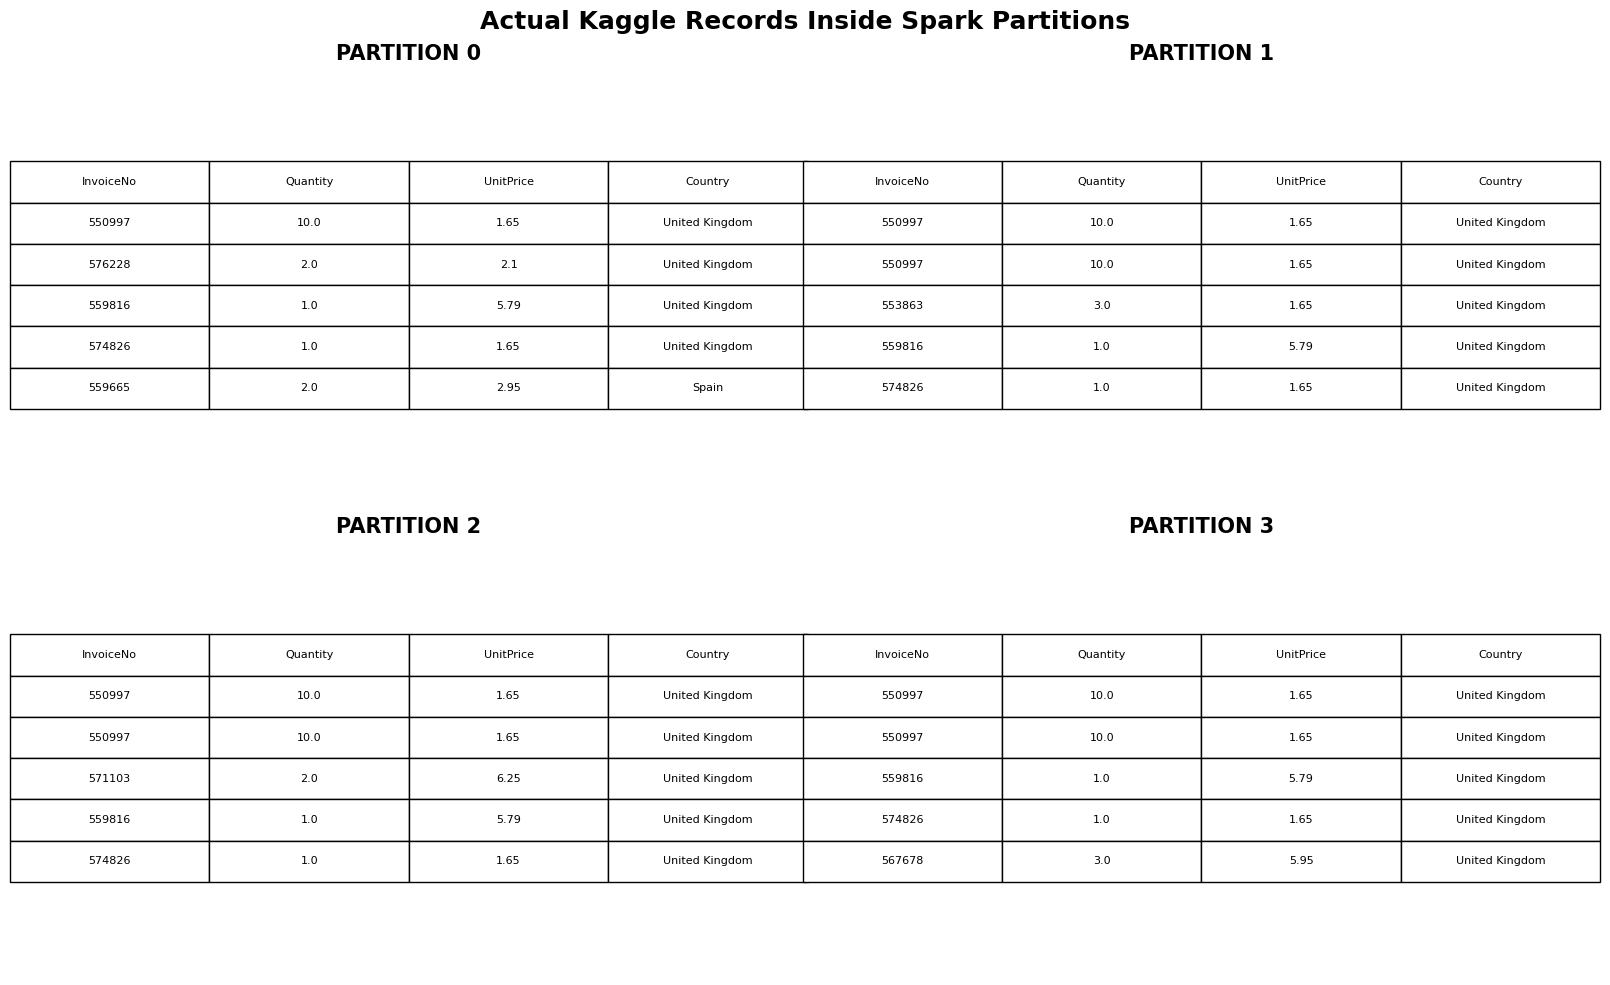

In [ ]:
import matplotlib.pyplot as plt
from pyspark.sql.functions import spark_partition_id

# Prepare partitioned DataFrame
df_partitioned = df_clean.repartition(4)

df_visual = df_partitioned.withColumn(
    "Partition_ID",
    spark_partition_id()
)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for p, ax in enumerate(axes):

    # Fetch sample records from this partition
    sample = (
        df_visual
        .filter(f"Partition_ID = {p}")
        .select("InvoiceNo", "Quantity", "UnitPrice", "Country")
        .limit(5)
        .toPandas()
    )

    ax.axis("off")
    ax.set_title(f"PARTITION {p}", fontsize=15, fontweight="bold")

    table = ax.table(
        cellText=sample.values,
        colLabels=sample.columns,
        loc="center",
        cellLoc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1.2, 2)

plt.suptitle(
    "Actual Kaggle Records Inside Spark Partitions",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Hadoop V/S SparK difference

       APACHE SPARK vs HADOOP MAPREDUCE
Total records: 524,878
Operation: Calculate total revenue by country

HADOOP MAPREDUCE-STYLE RESULT
Countries processed: 38
Average execution time: 2.1317 seconds

APACHE SPARK RESULT
Countries processed: 38
Number of partitions: 4
Average execution time: 0.7044 seconds

RESULT VERIFICATION: PASSED

                 PERFORMANCE COMPARISON
Hadoop-style average: 2.1317 seconds
Spark average:        0.7044 seconds
Spark was 3.03x faster in this run.


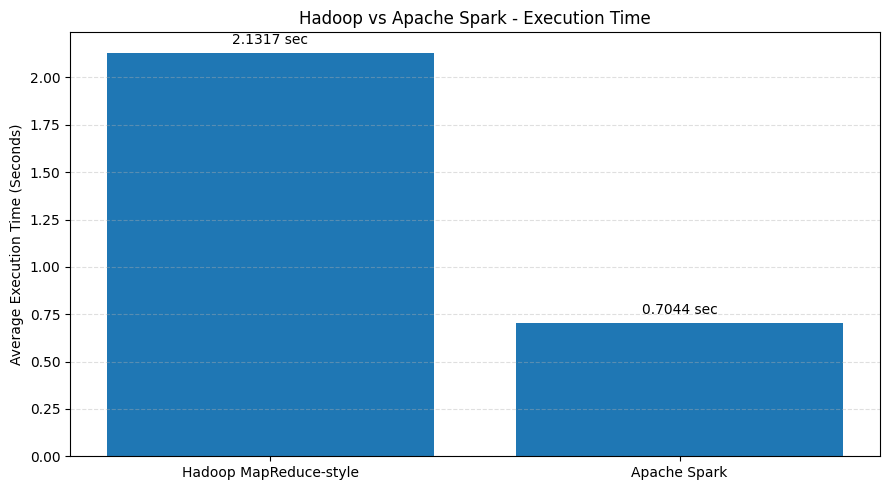

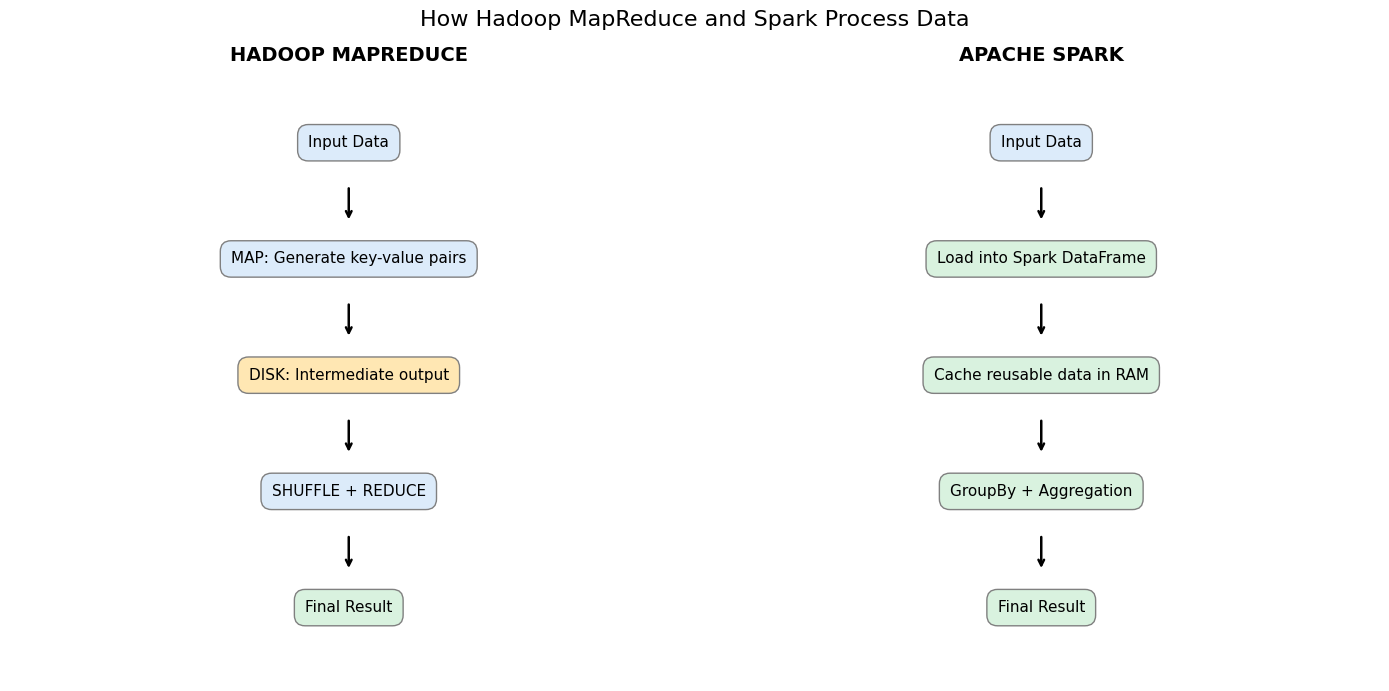

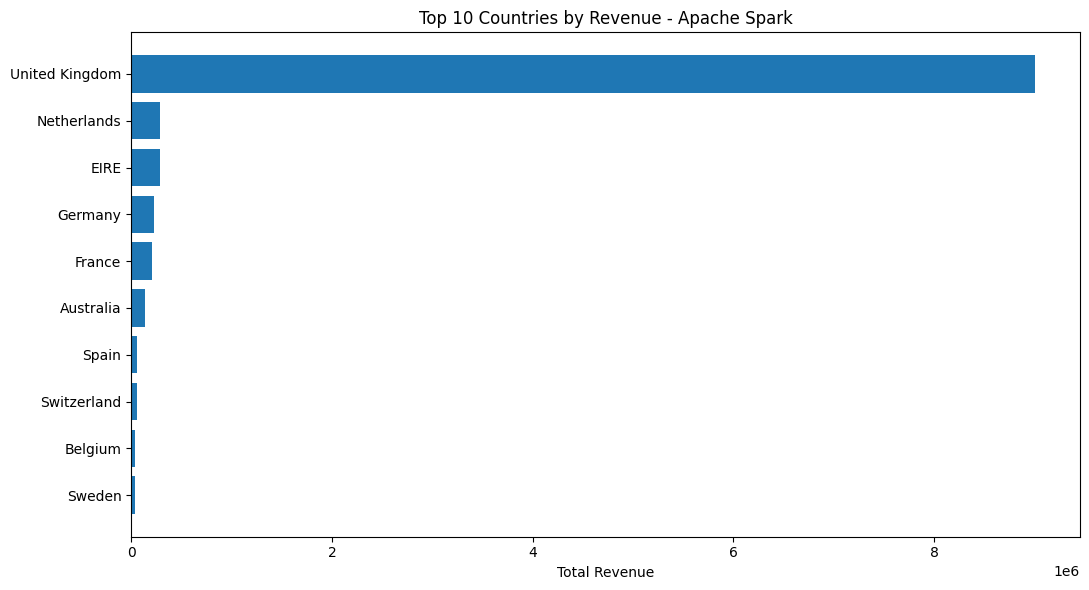


TOP 10 COUNTRIES
       Country  Total_Revenue
United Kingdom   9.001744e+06
   Netherlands   2.854463e+05
          EIRE   2.831405e+05
       Germany   2.286784e+05
        France   2.096254e+05
     Australia   1.384538e+05
         Spain   6.155856e+04
   Switzerland   5.706760e+04
       Belgium   4.119634e+04
        Sweden   3.836783e+04

DEMONSTRATION COMPLETED!


In [ ]:

# ============================================================
# APACHE SPARK vs HADOOP MAPREDUCE
# Practical Performance Demonstration using Online Retail Data
# ============================================================

import time
import os
import csv
import tempfile
import statistics
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F

# 1. PREPARE DATA
print("=" * 65)
print("       APACHE SPARK vs HADOOP MAPREDUCE")
print("=" * 65)

if "df_clean" not in globals():
    raise ValueError("Please run your data-cleaning cells first to create df_clean.")

# Use the same cleaned records for both demonstrations
pdf = df_clean.select(
    "Country", "Quantity", "UnitPrice"
).toPandas()

pdf["Quantity"] = pd.to_numeric(pdf["Quantity"], errors="coerce")
pdf["UnitPrice"] = pd.to_numeric(pdf["UnitPrice"], errors="coerce")
pdf = pdf.dropna(subset=["Country", "Quantity", "UnitPrice"])
pdf["Revenue"] = pdf["Quantity"] * pdf["UnitPrice"]

print("Total records:", f"{len(pdf):,}")
print("Operation: Calculate total revenue by country")

# ============================================================
# 2. HADOOP MAPREDUCE-STYLE PROCESSING
# Map -> Write intermediate data to disk -> Reduce
# This is a Python simulation, NOT actual Hadoop.
# ============================================================

def hadoop_mapreduce_simulation(data):
    with tempfile.TemporaryDirectory() as temp_dir:
        intermediate_file = os.path.join(temp_dir, "map_output.csv")

        # MAP PHASE: Generate country and revenue pairs
        with open(intermediate_file, "w", newline="") as file:
            writer = csv.writer(file)
            for row in data.itertuples(index=False):
                writer.writerow([row.Country, row.Revenue])

        # SHUFFLE + REDUCE PHASE: Read intermediate disk data
        totals = {}

        with open(intermediate_file, "r") as file:
            reader = csv.reader(file)
            for country, revenue in reader:
                totals[country] = totals.get(country, 0) + float(revenue)

        return totals


# Measure Hadoop-style processing (3 runs)
hadoop_times = []

for run in range(3):
    start = time.perf_counter()
    hadoop_result = hadoop_mapreduce_simulation(pdf)
    hadoop_times.append(time.perf_counter() - start)

hadoop_time = statistics.mean(hadoop_times)

print("\nHADOOP MAPREDUCE-STYLE RESULT")
print("Countries processed:", len(hadoop_result))
print("Average execution time:", round(hadoop_time, 4), "seconds")


# ============================================================
# 3. APACHE SPARK PROCESSING
# Distributed DataFrame -> GroupBy -> Aggregation
# Cache input to demonstrate reuse in memory.
# ============================================================

spark_pdf = pdf[["Country", "Revenue"]].copy()
spark_df = spark.createDataFrame(spark_pdf).repartition(4).cache()

# Materialize the cache before timing
spark_df.count()

spark_times = []

for run in range(3):
    start = time.perf_counter()

    spark_result = (
        spark_df
        .groupBy("Country")
        .agg(F.sum("Revenue").alias("Total_Revenue"))
    )

    spark_output = spark_result.collect()
    spark_times.append(time.perf_counter() - start)

spark_time = statistics.mean(spark_times)

print("\nAPACHE SPARK RESULT")
print("Countries processed:", len(spark_output))
print("Number of partitions:", spark_df.rdd.getNumPartitions())
print("Average execution time:", round(spark_time, 4), "seconds")


# ============================================================
# 4. VERIFY BOTH RESULTS
# ============================================================

spark_dictionary = {
    row["Country"]: row["Total_Revenue"]
    for row in spark_output
}

same_results = all(
    abs(hadoop_result[country] - spark_dictionary[country]) < 0.01
    for country in hadoop_result
)

print("\nRESULT VERIFICATION:", "PASSED" if same_results else "CHECK RESULTS")


# ============================================================
# 5. PERFORMANCE COMPARISON
# ============================================================

print("\n" + "=" * 65)
print("                 PERFORMANCE COMPARISON")
print("=" * 65)

print(f"Hadoop-style average: {hadoop_time:.4f} seconds")
print(f"Spark average:        {spark_time:.4f} seconds")

if spark_time < hadoop_time:
    print(f"Spark was {hadoop_time / spark_time:.2f}x faster in this run.")
else:
    print("Spark was not faster in this run. Timing depends on the environment.")

# Bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    ["Hadoop MapReduce-style", "Apache Spark"],
    [hadoop_time, spark_time]
)

plt.title("Hadoop vs Apache Spark - Execution Time")
plt.ylabel("Average Execution Time (Seconds)")
plt.bar_label(bars, fmt="%.4f sec", padding=4)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# ============================================================
# 6. ARCHITECTURE VISUALIZATION
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

def draw_flow(ax, title, steps):
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.axis("off")

    for i, (label, color) in enumerate(steps):
        y = 0.88 - i * 0.19
        ax.text(
            0.5, y, label,
            ha="center", va="center",
            fontsize=11,
            bbox=dict(boxstyle="round,pad=0.7", fc=color, ec="gray")
        )
        if i < len(steps) - 1:
            ax.annotate(
                "", xy=(0.5, y - 0.13), xytext=(0.5, y - 0.07),
                arrowprops=dict(arrowstyle="->", lw=1.8)
            )

draw_flow(
    axes[0],
    "HADOOP MAPREDUCE",
    [
        ("Input Data", "#DCEBFA"),
        ("MAP: Generate key-value pairs", "#DCEBFA"),
        ("DISK: Intermediate output", "#FFE7B3"),
        ("SHUFFLE + REDUCE", "#DCEBFA"),
        ("Final Result", "#D9F2DF")
    ]
)

draw_flow(
    axes[1],
    "APACHE SPARK",
    [
        ("Input Data", "#DCEBFA"),
        ("Load into Spark DataFrame", "#D9F2DF"),
        ("Cache reusable data in RAM", "#D9F2DF"),
        ("GroupBy + Aggregation", "#D9F2DF"),
        ("Final Result", "#D9F2DF")
    ]
)

plt.suptitle("How Hadoop MapReduce and Spark Process Data", fontsize=16)
plt.tight_layout()
plt.show()


# ============================================================
# 7. DISPLAY TOP 10 COUNTRIES BY REVENUE
# ============================================================

top_countries = (
    spark_result
    .orderBy(F.desc("Total_Revenue"))
    .limit(10)
    .toPandas()
)

plt.figure(figsize=(11, 6))
plt.barh(top_countries["Country"], top_countries["Total_Revenue"])
plt.xlabel("Total Revenue")
plt.title("Top 10 Countries by Revenue - Apache Spark")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\nTOP 10 COUNTRIES")
print(top_countries.to_string(index=False))

# Release cached data
spark_df.unpersist()

print("\nDEMONSTRATION COMPLETED!")


In [ ]:


# Cache the partitioned DataFrame
df_partitioned.cache()

# Trigger execution so the data is materialized in cache
df_partitioned.count()

print("Data cached successfully!")
print("Number of partitions:",
      df_partitioned.rdd.getNumPartitions())

print("Storage level:",
      df_partitioned.storageLevel)

Data cached successfully!
Number of partitions: 4
Storage level: Disk Memory Deserialized 1x Replicated


In [ ]:
# Create an RDD with sample data
data = list(range(1, 21))

rdd = spark.sparkContext.parallelize(data, 4)

print("Number of partitions:", rdd.getNumPartitions())

# Display original data
print("Original RDD:", rdd.collect())

Number of partitions: 4
Original RDD: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


In [ ]:
# Create an RDD with sample data
data = list(range(1, 21))

rdd = spark.sparkContext.parallelize(data, 4)

print("Number of partitions:", rdd.getNumPartitions())

# Display original data
print("Original RDD:", rdd.collect())

Number of partitions: 4
Original RDD: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


In [ ]:
# Define the RDD steps to create the lineage first
rdd_step1 = rdd.filter(lambda x: x > 5)
rdd_step2 = rdd_step1.map(lambda x: x * 10)

# Display RDD lineage information
print(rdd_step2.toDebugString().decode("utf-8"))

(4) PythonRDD[171] at RDD at PythonRDD.scala:57 []
 |  ParallelCollectionRDD[170] at readRDDFromFile at PythonRDD.scala:298 []


## 9. Transformations and actions

**Transformations** describe how to create a new DataFrame: `filter()`, `select()`, `withColumn()`, `groupBy()`.

**Actions** request a result or save data: `show()`, `count()`, `collect()`, `write`.

Identify these in the example.

In [ ]:
# TRANSFORMATION: describe which rows to keep
high_quantity = df_partitioned.filter(col("Quantity") > 10)

# TRANSFORMATION: select columns
selected = high_quantity.select(
    "InvoiceNo", "StockCode", "Quantity", "UnitPrice", "Country"
)

# ACTION: asks Spark to execute and display rows
selected.show(10, truncate=False)

+---------+---------+--------+---------+--------------+
|InvoiceNo|StockCode|Quantity|UnitPrice|Country       |
+---------+---------+--------+---------+--------------+
|565796   |20984    |24.0    |0.29     |United Kingdom|
|539635   |48173C   |12.0    |6.75     |United Kingdom|
|571660   |22816    |12.0    |0.42     |United Kingdom|
|577756   |35970    |12.0    |1.69     |United Kingdom|
|570514   |84879    |36.0    |1.69     |United Kingdom|
|566572   |21917    |24.0    |0.42     |United Kingdom|
|540691   |22772    |18.0    |1.49     |United Kingdom|
|565932   |84978    |12.0    |1.25     |United Kingdom|
|562376   |23546    |25.0    |0.42     |United Kingdom|
|541430   |84991    |120.0   |0.42     |Portugal      |
+---------+---------+--------+---------+--------------+
only showing top 10 rows


## 10. Process transactions: calculate sales

For this educational example:

**TotalSales = Quantity × UnitPrice**

This does not account for shipping, tax, discounts or accounting adjustments.

In [ ]:
sales_df = df_partitioned.withColumn(
    "TotalSales", col("Quantity") * col("UnitPrice")
)

sales_df.select(
    "InvoiceNo", "Description", "Quantity",
    "UnitPrice", "TotalSales", "Country"
).show(10, truncate=False)

+---------+----------------------------------+--------+---------+------------------+--------------+
|InvoiceNo|Description                       |Quantity|UnitPrice|TotalSales        |Country       |
+---------+----------------------------------+--------+---------+------------------+--------------+
|554514   |CAKE STAND VICTORIAN FILIGREE MED |12.0    |5.79     |69.48             |United Kingdom|
|555276   |LOVEBIRD HANGING DECORATION WHITE |3.0     |1.63     |4.89              |United Kingdom|
|575930   |KINGS CHOICE TEA CADDY            |1.0     |5.79     |5.79              |United Kingdom|
|544598   |LUNCH BAG SUKI DESIGN             |2.0     |4.13     |8.26              |United Kingdom|
|579508   |ROLL WRAP VINTAGE CHRISTMAS       |4.0     |2.46     |9.84              |United Kingdom|
|562934   |RETROSPOT PARTY BAG + STICKER SET |1.0     |3.29     |3.29              |United Kingdom|
|566258   |ASSORTED COLOUR BIRD ORNAMENT     |40.0    |1.69     |67.6              |United Kingdom|


## 11. Business analysis
Now answer real business questions using Spark aggregations.

### 11.1 Total revenue

In [ ]:
sales_df.agg(
    spark_round(spark_sum("TotalSales"), 2).alias("TotalRevenue")
).show()

+------------+
|TotalRevenue|
+------------+
|1.06421108E7|
+------------+



### 11.2 Revenue by country

In [ ]:
country_sales = (
    sales_df.groupBy("Country")
    .agg(
        spark_round(spark_sum("TotalSales"), 2).alias("Revenue"),
        spark_count("*").alias("TransactionRows")
    )
    .orderBy(desc("Revenue"))
)
country_sales.show(15, truncate=False)

+--------------+----------+---------------+
|Country       |Revenue   |TransactionRows|
+--------------+----------+---------------+
|United Kingdom|9001744.09|479985         |
|Netherlands   |285446.34 |2359           |
|EIRE          |283140.52 |7879           |
|Germany       |228678.4  |9025           |
|France        |209625.37 |8392           |
|Australia     |138453.81 |1181           |
|Spain         |61558.56  |2479           |
|Switzerland   |57067.6   |1958           |
|Belgium       |41196.34  |2031           |
|Sweden        |38367.83  |450            |
|Japan         |37416.37  |321            |
|Norway        |36165.44  |1071           |
|Portugal      |33683.05  |1492           |
|Finland       |22546.08  |685            |
|Singapore     |21279.29  |222            |
+--------------+----------+---------------+
only showing top 15 rows


### 11.3 Top products by units sold

In [ ]:
top_products = (
    sales_df.groupBy("StockCode", "Description")
    .agg(
        spark_sum("Quantity").alias("UnitsSold"),
        spark_round(spark_sum("TotalSales"), 2).alias("Revenue")
    )
    .orderBy(desc("UnitsSold"))
)
top_products.show(10, truncate=False)

+---------+----------------------------------+---------+---------+
|StockCode|Description                       |UnitsSold|Revenue  |
+---------+----------------------------------+---------+---------+
|23843    |PAPER CRAFT , LITTLE BIRDIE       |80995.0  |168469.6 |
|23166    |MEDIUM CERAMIC TOP STORAGE JAR    |78033.0  |81700.92 |
|84077    |WORLD WAR 2 GLIDERS ASSTD DESIGNS |54951.0  |13814.01 |
|85099B   |JUMBO BAG RED RETROSPOT           |48371.0  |94159.81 |
|85123A   |WHITE HANGING HEART T-LIGHT HOLDER|37580.0  |104284.24|
|22197    |POPCORN HOLDER                    |36749.0  |34288.67 |
|21212    |PACK OF 72 RETROSPOT CAKE CASES   |36396.0  |21246.45 |
|84879    |ASSORTED COLOUR BIRD ORNAMENT     |36362.0  |58927.62 |
|23084    |RABBIT NIGHT LIGHT                |30739.0  |66870.03 |
|22492    |MINI PAINT SET VINTAGE            |26633.0  |16937.82 |
+---------+----------------------------------+---------+---------+
only showing top 10 rows


### 11.4 Monthly revenue

In [ ]:
monthly_sales = (
    sales_df.withColumn("YearMonth", date_format("InvoiceDate", "yyyy-MM"))
    .groupBy("YearMonth")
    .agg(spark_round(spark_sum("TotalSales"), 2).alias("Revenue"))
    .orderBy("YearMonth")
)
monthly_sales.show(20, truncate=False)

+---------+----------+
|YearMonth|Revenue   |
+---------+----------+
|2010-12  |821452.73 |
|2011-01  |689811.61 |
|2011-02  |522545.56 |
|2011-03  |716215.26 |
|2011-04  |536968.49 |
|2011-05  |769296.61 |
|2011-06  |760547.01 |
|2011-07  |718076.12 |
|2011-08  |757841.38 |
|2011-09  |1056435.19|
|2011-10  |1151263.73|
|2011-11  |1503866.78|
|2011-12  |637790.33 |
+---------+----------+



## 12. Spark SQL
A DataFrame can be registered as a temporary view, then queried using familiar SQL.

In [ ]:
sales_df.createOrReplaceTempView("retail_sales")

query_result = spark.sql(
    "SELECT Country, ROUND(SUM(TotalSales), 2) AS Revenue "
    "FROM retail_sales GROUP BY Country ORDER BY Revenue DESC LIMIT 10"
)
query_result.show(truncate=False)

+--------------+----------+
|Country       |Revenue   |
+--------------+----------+
|United Kingdom|9001744.09|
|Netherlands   |285446.34 |
|EIRE          |283140.52 |
|Germany       |228678.4  |
|France        |209625.37 |
|Australia     |138453.81 |
|Spain         |61558.56  |
|Switzerland   |57067.6   |
|Belgium       |41196.34  |
|Sweden        |38367.83  |
+--------------+----------+



## 13. Lazy evaluation

Spark is lazy: transformations generally build a plan rather than immediately processing all data. An action triggers execution to produce a result.

Here, `filter()` and `select()` are transformations. `show()` is the action.

In [ ]:
lazy_example = (
    df_partitioned
    .filter(col("Quantity") > 5)
    .select("InvoiceNo", "Quantity", "UnitPrice", "Country")
)

print("Transformations have described the work. Now show() requests results.")
lazy_example.show(5)

Transformations have described the work. Now show() requests results.
+---------+--------+---------+--------------+
|InvoiceNo|Quantity|UnitPrice|       Country|
+---------+--------+---------+--------------+
|   550997|    10.0|     1.65|United Kingdom|
|   566818|    12.0|     1.25|United Kingdom|
|   557057|    36.0|     0.19|United Kingdom|
|   581133|    12.0|     0.79|United Kingdom|
|   559128|     6.0|     2.08|United Kingdom|
+---------+--------+---------+--------------+
only showing top 5 rows


## 14. View the execution plan
`explain()` shows how Spark plans the query. Look for operations such as Filter, Project, Exchange and scan. Exact plan text depends on Spark version and query.

In [ ]:
lazy_example.explain(extended=True)

== Parsed Logical Plan ==
'Project ['InvoiceNo, 'Quantity, 'UnitPrice, 'Country]
+- Filter (Quantity#700 > cast(5 as double))
   +- Repartition 4, true
      +- Filter isnotnull(InvoiceDate#702)
         +- Filter ((Quantity#700 > cast(0 as double)) AND (UnitPrice#701 > cast(0 as double)))
            +- Project [InvoiceNo#23, StockCode#24, Description#25, Quantity#700, to_timestamp(InvoiceDate#27, Some(M/d/yyyy H:mm), TimestampType, Some(Etc/UTC), true) AS InvoiceDate#702, UnitPrice#701, CustomerID#29, Country#30]
               +- Project [InvoiceNo#23, StockCode#24, Description#25, Quantity#700, InvoiceDate#27, cast(UnitPrice#28 as double) AS UnitPrice#701, CustomerID#29, Country#30]
                  +- Project [InvoiceNo#23, StockCode#24, Description#25, cast(Quantity#26 as double) AS Quantity#700, InvoiceDate#27, UnitPrice#28, CustomerID#29, Country#30]
                     +- Deduplicate [Quantity#26, UnitPrice#28, StockCode#24, Description#25, InvoiceDate#27, InvoiceNo#23, Coun

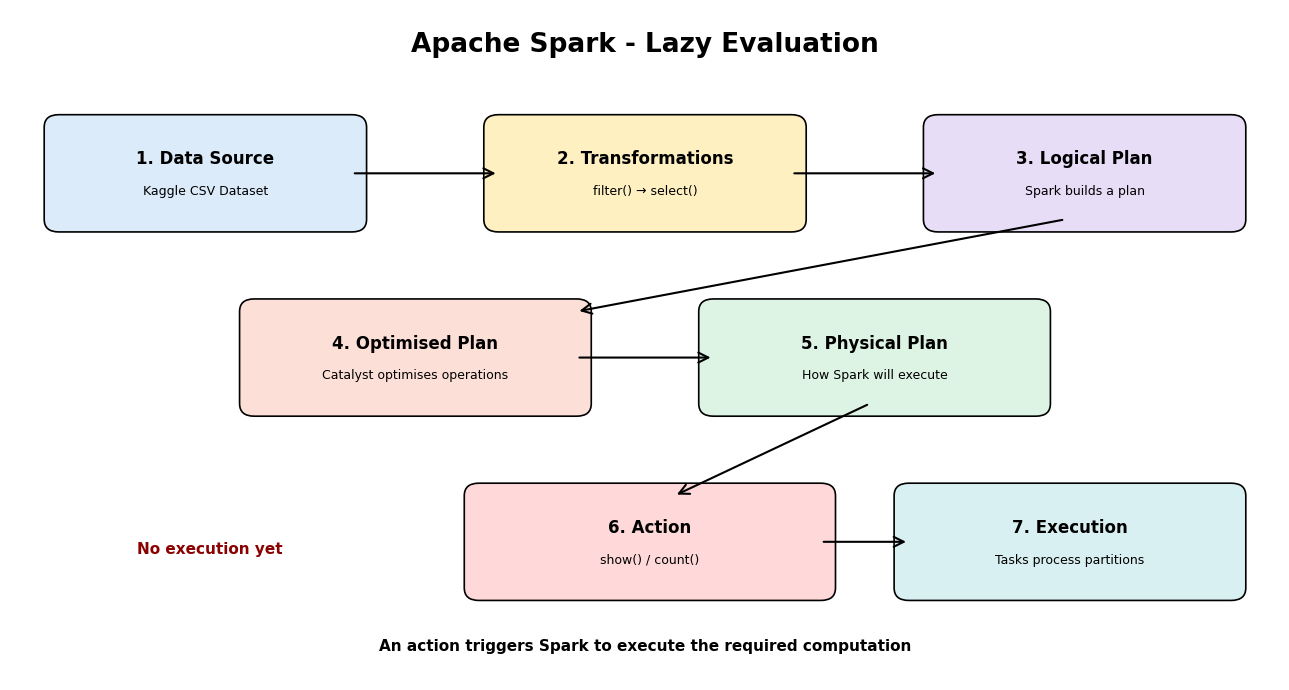

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13, 7))
ax.set_xlim(0, 13)
ax.set_ylim(0, 8)
ax.axis("off")

def draw_box(x, y, w, h, title, subtitle, color):
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.15",
        facecolor=color,
        edgecolor="black",
        linewidth=1.2
    )
    ax.add_patch(box)
    ax.text(x+w/2, y+h*0.65, title,
            ha="center", va="center",
            fontsize=12, fontweight="bold")
    ax.text(x+w/2, y+h*0.30, subtitle,
            ha="center", va="center", fontsize=9)

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="->", mutation_scale=18,
        linewidth=1.5
    ))

ax.text(6.5, 7.5, "Apache Spark - Lazy Evaluation",
        ha="center", fontsize=19, fontweight="bold")

draw_box(0.5, 5.5, 3, 1.1, "1. Data Source",
         "Kaggle CSV Dataset", "#DCEBFA")

draw_box(5, 5.5, 3, 1.1, "2. Transformations",
         "filter() → select()", "#FFF0C2")

draw_box(9.5, 5.5, 3, 1.1, "3. Logical Plan",
         "Spark builds a plan", "#E8DDF7")

arrow(3.5, 6.05, 5, 6.05)
arrow(8, 6.05, 9.5, 6.05)

draw_box(2.5, 3.3, 3.3, 1.1, "4. Optimised Plan",
         "Catalyst optimises operations", "#FCE0D8")

draw_box(7.2, 3.3, 3.3, 1.1, "5. Physical Plan",
         "How Spark will execute", "#DDF3E4")

arrow(10.8, 5.5, 5.8, 4.4)
arrow(5.8, 3.85, 7.2, 3.85)

draw_box(4.8, 1.1, 3.5, 1.1, "6. Action",
         "show() / count()", "#FFD9D9")

draw_box(9.2, 1.1, 3.3, 1.1, "7. Execution",
         "Tasks process partitions", "#D9F0F2")

arrow(8.8, 3.3, 6.8, 2.2)
arrow(8.3, 1.65, 9.2, 1.65)

ax.text(1.3, 1.5, "No execution yet",
        fontsize=11, color="darkred", fontweight="bold")

ax.text(6.5, 0.35,
        "An action triggers Spark to execute the required computation",
        ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()


In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col

# Ensure SparkSession is active if it was stopped
spark = (
    SparkSession.builder
    .appName("OnlineRetailSparkSeminar")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

# Re-create df_partitioned if necessary from df_clean
if 'df_partitioned' not in locals() or 'df_clean' not in locals():
    raise ValueError("Please run the setup and data loading cells above first.")

# STEP 1: Create transformations
step1 = df_partitioned.filter(col("Quantity") > 5)

step2 = step1.select(
    "InvoiceNo",
    "Quantity",
    "UnitPrice",
    "Country"
)

print("Transformations created!")
print("Spark has prepared the query plan.")
print("No result has been requested yet.")

Transformations created!
Spark has prepared the query plan.
No result has been requested yet.


In [ ]:

print("LOGICAL AND PHYSICAL EXECUTION PLANS")

step2.explain(extended=True)


LOGICAL AND PHYSICAL EXECUTION PLANS
== Parsed Logical Plan ==
'Project ['InvoiceNo, 'Quantity, 'UnitPrice, 'Country]
+- Filter (Quantity#700 > cast(5 as double))
   +- Repartition 4, true
      +- Filter isnotnull(InvoiceDate#702)
         +- Filter ((Quantity#700 > cast(0 as double)) AND (UnitPrice#701 > cast(0 as double)))
            +- Project [InvoiceNo#23, StockCode#24, Description#25, Quantity#700, to_timestamp(InvoiceDate#27, Some(M/d/yyyy H:mm), TimestampType, Some(Etc/UTC), true) AS InvoiceDate#702, UnitPrice#701, CustomerID#29, Country#30]
               +- Project [InvoiceNo#23, StockCode#24, Description#25, Quantity#700, InvoiceDate#27, cast(UnitPrice#28 as double) AS UnitPrice#701, CustomerID#29, Country#30]
                  +- Project [InvoiceNo#23, StockCode#24, Description#25, cast(Quantity#26 as double) AS Quantity#700, InvoiceDate#27, UnitPrice#28, CustomerID#29, Country#30]
                     +- Deduplicate [Quantity#26, UnitPrice#28, StockCode#24, Description#2

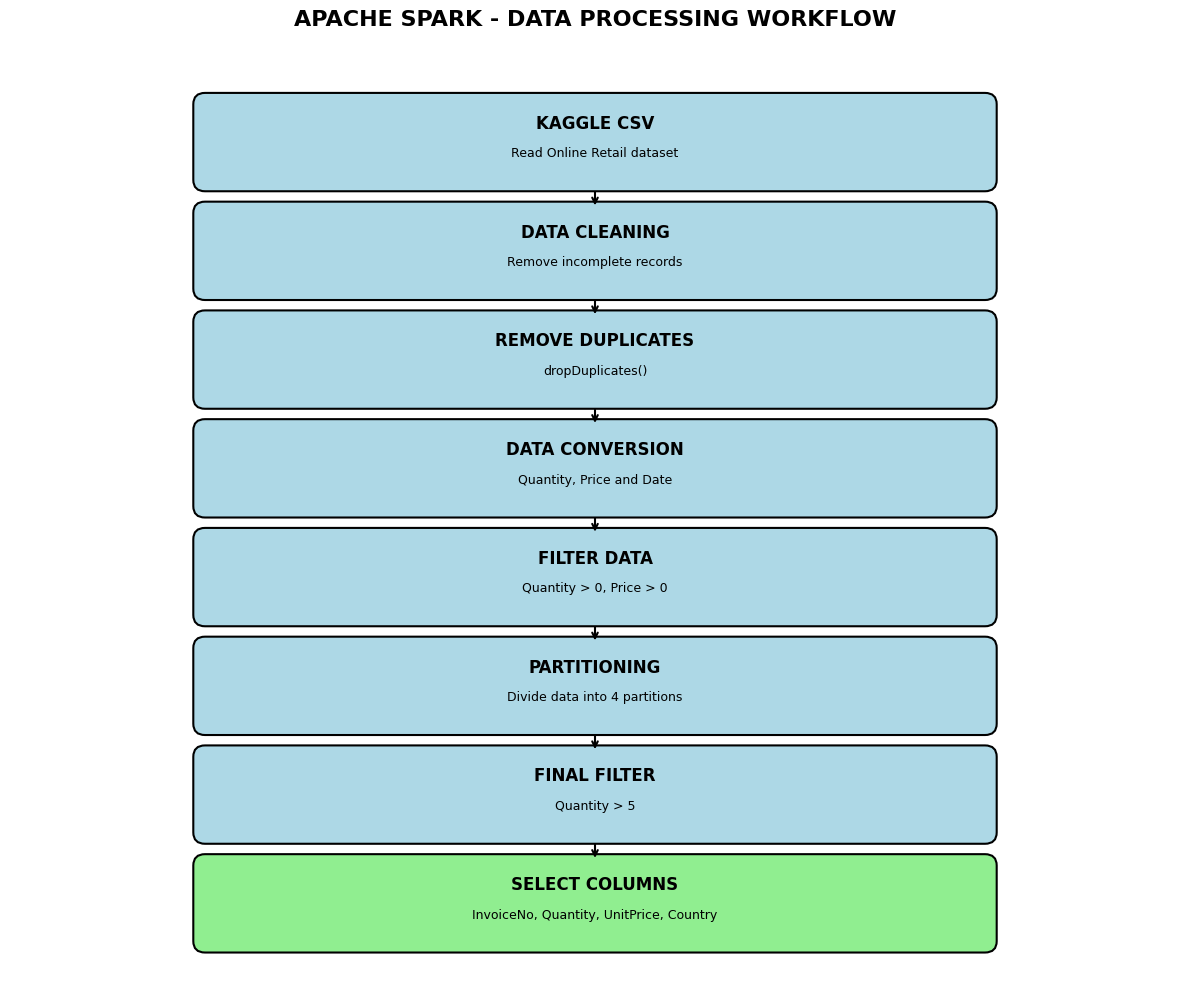

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

steps = [
    ("KAGGLE CSV", "Read Online Retail dataset"),
    ("DATA CLEANING", "Remove incomplete records"),
    ("REMOVE DUPLICATES", "dropDuplicates()"),
    ("DATA CONVERSION", "Quantity, Price and Date"),
    ("FILTER DATA", "Quantity > 0, Price > 0"),
    ("PARTITIONING", "Divide data into 4 partitions"),
    ("FINAL FILTER", "Quantity > 5"),
    ("SELECT COLUMNS", "InvoiceNo, Quantity, UnitPrice, Country")
]

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

for i, (title, desc) in enumerate(steps):
    y = 9 - i * 1.15

    box = FancyBboxPatch(
        (2, y - 0.55), 8, 0.8,
        boxstyle="round,pad=0.12",
        linewidth=1.5,
        edgecolor="black",
        facecolor="lightblue" if i < 7 else "lightgreen"
    )

    ax.add_patch(box)
    ax.text(6, y, title, ha="center",
            fontsize=12, fontweight="bold")
    ax.text(6, y - 0.3, desc, ha="center", fontsize=9)

    if i < len(steps) - 1:
        ax.annotate(
            "", xy=(6, y - 0.85),
            xytext=(6, y - 0.65),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

plt.title(
    "APACHE SPARK - DATA PROCESSING WORKFLOW",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
step1 = df_partitioned.filter("Quantity > 5")

step2 = step1.select(
    "InvoiceNo",
    "Quantity",
    "UnitPrice",
    "Country"
)


In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, to_timestamp

# Ensure we have a fresh, active SparkSession
spark = (
    SparkSession.builder
    .appName("OnlineRetailSparkSeminar")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

# Re-load and re-clean raw data to bind all lineage to the active Spark session
df_raw = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("encoding", "ISO-8859-1")
    .csv(csv_path)
)

df_clean = (
    df_raw
    .dropna(subset=required)
    .dropDuplicates()
    .withColumn("Quantity", col("Quantity").cast("double"))
    .withColumn("UnitPrice", col("UnitPrice").cast("double"))
    .withColumn("InvoiceDate", to_timestamp(col("InvoiceDate"), "M/d/yyyy H:mm"))
    .filter((col("Quantity") > 0) & (col("UnitPrice") > 0))
    .filter(col("InvoiceDate").isNotNull())
)

df_partitioned = df_clean.repartition(4)

# Run the transformations
step1 = df_partitioned.filter(col("Quantity") > 5)
step2 = step1.select(
    "InvoiceNo",
    "Quantity",
    "UnitPrice",
    "Country"
)

# Perform the action on the fresh lineage
step2.show(10)

+---------+--------+---------+--------------+
|InvoiceNo|Quantity|UnitPrice|       Country|
+---------+--------+---------+--------------+
|   550997|    10.0|     1.65|United Kingdom|
|   566818|    12.0|     1.25|United Kingdom|
|   557057|    36.0|     0.19|United Kingdom|
|   581133|    12.0|     0.79|United Kingdom|
|   559128|     6.0|     2.08|United Kingdom|
|   564565|    12.0|     2.95|          EIRE|
|   571671|    12.0|     0.42|United Kingdom|
|   570443|    24.0|      2.1|United Kingdom|
|   548203|    18.0|     2.95|United Kingdom|
|   580116|    24.0|     4.15|United Kingdom|
+---------+--------+---------+--------------+
only showing top 10 rows


### Jobs, stages and tasks
- An **action** can trigger a Spark job.
- A job is divided into **stages**.
- A stage contains **tasks**, commonly one task per partition.
- Shuffle operations can create stage boundaries.

The Spark UI can show jobs and stages in more detail. In hosted Colab, exposing its UI may need extra setup, so `explain()` is the reliable demonstration here.

## 15. Visualise results

Spark performs the data processing. We bring only small aggregated results into Pandas for plotting.

**Do not use `toPandas()` on the entire retail dataset**: it collects data into notebook memory and may overwhelm it.

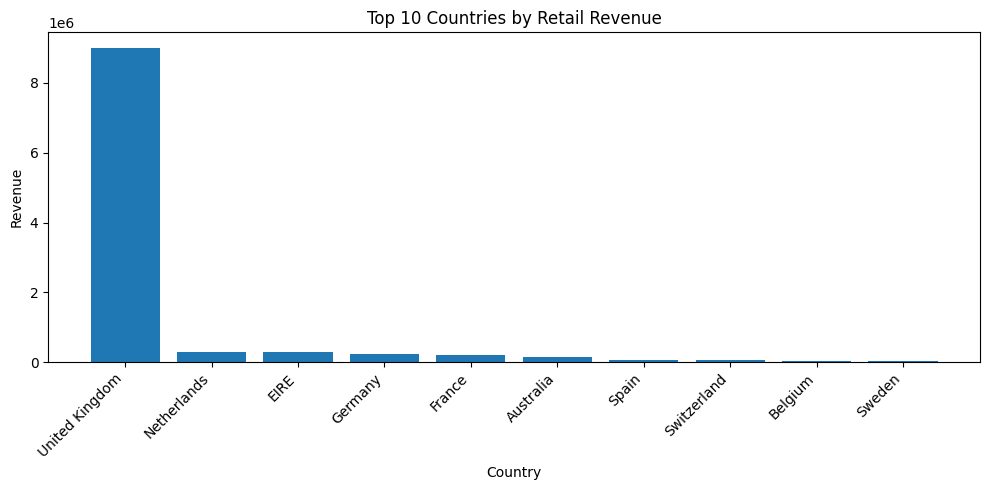

In [ ]:
import matplotlib.pyplot as plt

country_plot = country_sales.limit(10).toPandas()
plt.figure(figsize=(10, 5))
plt.bar(country_plot["Country"], country_plot["Revenue"])
plt.title("Top 10 Countries by Retail Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

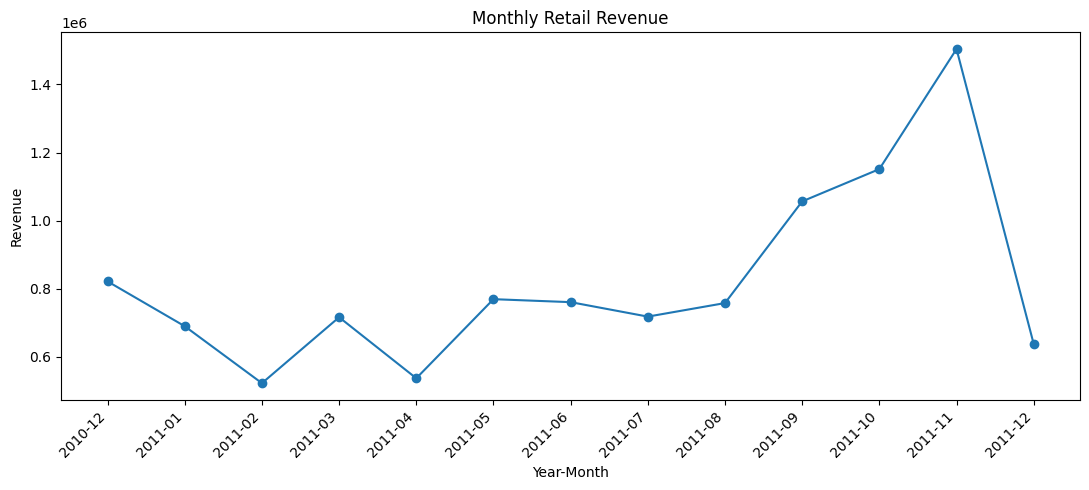

In [ ]:
monthly_plot = monthly_sales.toPandas()
plt.figure(figsize=(11, 5))
plt.plot(monthly_plot["YearMonth"], monthly_plot["Revenue"], marker="o")
plt.title("Monthly Retail Revenue")
plt.xlabel("Year-Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 16. Real-time processing: Structured Streaming

The Kaggle CSV is historical data, so reading it is **batch processing**. To demonstrate incoming data, Spark provides a built-in `rate` source.

It generates rows with a timestamp and increasing value. We process generated rows in micro-batches and print them.

**This is a live simulation, not an actual live online shop feed.** Real systems can connect Structured Streaming to sources such as Kafka or streaming files.

In [ ]:
live_stream = (
    spark.readStream
    .format("rate")
    .option("rowsPerSecond", 2)
    .load()
)

live_processed = live_stream.withColumn(
    "demo_value_x_10", col("value") * 10
)

stream_query = (
    live_processed.writeStream
    .format("console")
    .outputMode("append")
    .option("truncate", "false")
    .trigger(processingTime="2 seconds")
    .option("numRows", 10)
    .start()
)

print("Streaming started. Observe the new micro-batches.")
stream_query.awaitTermination(10)
stream_query.stop()
print("Streaming demonstration stopped.")

Streaming started. Observe the new micro-batches.
Streaming demonstration stopped.


### What happened?
1. Spark started a streaming query.
2. The rate source generated new rows.
3. Spark grouped them into micro-batches.
4. A transformation created a new column.
5. The console displayed the output.

| Batch processing | Streaming |
|---|---|
| Processes stored data | Processes data as it arrives |
| Example: Kaggle CSV analysis | Example: incoming transaction monitoring |
| Finite job | Usually keeps running until stopped |

Structured Streaming commonly uses micro-batch execution; it does not necessarily process every event individually at the exact instant it arrives.

## 17. Fault tolerance and RDD

**RDD** means **Resilient Distributed Dataset**.
- **Resilient:** Spark can recover lost partitions by recomputing them from lineage, when source data is available.
- **Distributed:** Data is divided into partitions.
- **Dataset:** A collection of records.

You do not need to simulate a machine failure. Explain that Spark can remember the operations used to create data and may recompute a lost partition.

## 18. Complete project recap

1. Start Spark by creating a SparkSession.
2. Download the Kaggle dataset.
3. Load CSV data into a DataFrame.
4. Inspect rows, columns, schema and missing values.
5. Clean the data for the selected analysis.
6. Divide data into partitions.
7. Apply transformations and actions.
8. Calculate revenue, top products and country/month summaries.
9. Explain lazy evaluation, jobs, stages, tasks and execution plans.
10. Visualise small aggregated results.
11. Demonstrate continuously arriving data using Structured Streaming.

### Suggested seminar closing
"Apache Spark reads data from different sources, divides work into partitions, processes data in parallel and produces useful results. With Structured Streaming, Spark can also process continuously arriving data. This makes Spark useful for big-data analytics and real-time data applications."

## 19. Beginner viva questions

1. **What is Apache Spark?** A data-processing engine for large datasets, including parallel and distributed processing.
2. **What is PySpark?** The Python API for Apache Spark.
3. **What is SparkSession?** The main entry point for DataFrames and Spark SQL.
4. **What is a DataFrame?** A distributed table-like structure with named columns.
5. **What is a partition?** A logical chunk of data Spark can process separately.
6. **What is an RDD?** Resilient Distributed Dataset, Spark's lower-level distributed collection abstraction.
7. **What is lazy evaluation?** Spark delays executing transformations until an action needs a result.
8. **Examples of transformations?** `filter()`, `select()`, `withColumn()`, `groupBy()`.
9. **Examples of actions?** `show()`, `count()`, `collect()`, writing output.
10. **What is Structured Streaming?** Spark's engine for processing continuously arriving data, commonly using micro-batches.
11. **Is Kaggle CSV live data?** No. It is historical batch data. The rate source separately simulates incoming data.
12. **What does `local[*]` mean?** Run Spark locally using available CPU cores.

## 20. Practice exercises
Try finding unique countries, unique invoice numbers, top countries by transaction-row count, average unit price by country, and the month with the highest revenue.

In [ ]:
df_clean.select("Country").distinct().count()  # Example: count unique countries

38

## 21. Stop Spark
Stop any remaining streaming query and release Spark resources when finished.

In [ ]:
for active_query in spark.streams.active:
    active_query.stop()

spark.stop()
print("Spark session stopped.")

Spark session stopped.


---
## Presenter reminders
- Practise the notebook before presenting.
- Keep the dataset downloaded before class if internet may be unreliable.
- Do not collect or convert the full dataset to Pandas.
- If Colab restarts, rerun installation, Spark initialization and dataset download.
- Exact row counts and results can change if Kaggle updates the dataset.
- Be clear that `local[*]` is a local demonstration, not a multi-node cluster.